# The regions do not sum to the total: rolling up a hierarchy extracted with defects

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/hierarchy-reconciliation/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/hierarchy-reconciliation/demo.ipynb)

The cost report by region does not tie to the ledger, or it ties and the regions are still wrong. The cause is
usually the hierarchy, not the postings: a parent-child extract where moved cost centres kept their old row, a
retired area left orphans, and one mis-keyed parent field made a loop. This notebook builds a fictional hierarchy
with those defects, rolls a year of postings up five ways, and scores every posted dollar against the truth.

1. The engine
2. What a validator finds
3. Five roll-ups, per dollar
4. The plug
5. Which parent row to keep
6. What no roll-up rule can place
7. The chart
8. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Seeded (`Random(210)`), every cost centre fictional, and
every number below matches `evidence.txt` exactly. The extract is a list of (child, parent, load) rows; the truth is
a single-parent map the simulation keeps aside.

In [1]:
from __future__ import annotations

import json
import random
from collections import defaultdict
from typing import Dict, List, Optional, Set, Tuple

import matplotlib.pyplot as plt


class _E:  # evidence.py refers to the engine as E
    pass

SEED = 210


ROOT = "TOTAL"


REGIONS = ["North", "South", "East", "West", "Central"]


UNASSIGNED = "Unassigned"


OTHER = "Other (plug)"


METHODS = ["naive_walk", "plug", "first_parent", "latest_parent", "validated"]


Row = Dict[str, object]


def make_world(seed: int = SEED) -> dict:
    """True tree, the defective extract of it, and the postings."""
    rng = random.Random(seed)
    parent: Dict[str, str] = {r: ROOT for r in REGIONS}
    areas: List[str] = []
    leaves: List[str] = []
    n = 100
    for ri, r in enumerate(REGIONS):
        for ai in range(rng.randint(4, 6)):
            a = f"A{ri + 1}{ai + 1}"
            parent[a] = r
            areas.append(a)
            for _ in range(rng.randint(3, 8)):
                leaves.append(f"CC{n}")
                parent[f"CC{n}"] = a
                n += 1
    extract: List[Row] = [{"child": c, "parent": p, "load": rng.randint(0, 40)} for c, p in parent.items()]
    by_child = {row["child"]: row for row in extract}
    pool = leaves[:]
    rng.shuffle(pool)
    moved, orphans = pool[:12], pool[12:18]
    for c in moved:  # moved to another area; the old row was never end-dated
        old = by_child[c]
        new = rng.choice([a for a in areas if a != old["parent"]])
        parent[c] = new
        extract.append({"child": c, "parent": new, "load": int(old["load"]) + rng.randint(30, 200)})
    for i, c in enumerate(orphans):  # parent area retired and removed from the extract; the child row was not
        by_child[c]["parent"] = f"Z{i + 1:02d}"
    cyc = rng.choice(areas)
    kid = next(c for c in leaves if parent[c] == cyc and c not in moved and c not in orphans)
    by_child[cyc]["parent"] = kid  # the area's parent field was keyed with one of its own children
    rng.shuffle(extract)
    new_ccs = []
    for _ in range(4):  # new cost centres that post before they reach the extract
        c = f"CC{n}"
        n += 1
        parent[c] = rng.choice(areas)
        new_ccs.append(c)
    posts: List[Tuple[str, int]] = []
    for c in leaves + new_ccs:
        size = rng.choice([1, 1, 2, 3])
        posts += [(c, size * rng.randint(400, 9000)) for _ in range(rng.randint(8, 16))]
    for a in areas:  # area-level adjustments (accruals, shared costs) posted above the leaves
        if rng.random() < 0.4:
            posts += [(a, rng.randint(2000, 25000)) for _ in range(rng.randint(1, 3))]
    return {"parent": parent, "extract": extract, "posts": posts, "moved": moved, "orphans": orphans,
            "cycle": (cyc, kid), "new_ccs": new_ccs, "areas": areas, "leaves": leaves}


def region_of(parent: Dict[str, str], node: str) -> Optional[str]:
    """Walk up a single-parent map; None if it never reaches a region (orphan, cycle, unknown)."""
    seen: Set[str] = set()
    while node not in REGIONS:
        if node in seen or node not in parent:
            return None
        seen.add(node)
        node = parent[node]
    return node


def amounts(posts: List[Tuple[str, int]]) -> Dict[str, float]:
    out: Dict[str, float] = defaultdict(float)
    for c, a in posts:
        out[c] += a
    return out


def truth(w: dict) -> Dict[str, float]:
    out: Dict[str, float] = defaultdict(float)
    for c, a in amounts(w["posts"]).items():
        out[region_of(w["parent"], c)] += a
    return out


def walk(kids: Dict[str, List[str]], amt: Dict[str, float], node: str, path: Set[str], leaves_only: bool) -> float:
    """Recursive descent along every edge, as a recursive CTE does. The path guard stops at a cycle; nothing stops a
    child listed under two parents from being summed twice."""
    if node in path:
        return 0.0
    ch = kids.get(node, [])
    own = amt.get(node, 0.0) if (not ch or not leaves_only) else 0.0
    return own + sum(walk(kids, amt, c, path | {node}, leaves_only) for c in ch)


def one_parent(extract: List[Row], how: str) -> Dict[str, str]:
    """Keep one row per child: the first in file order, or the latest load."""
    out: Dict[str, str] = {}
    best: Dict[str, int] = {}
    for row in extract:
        c, p, ld = str(row["child"]), str(row["parent"]), int(row["load"])
        if how == "first" and c in out:
            continue
        if how == "latest" and c in best and best[c] >= ld:
            continue
        out[c], best[c] = p, ld
    return out


def rollup(w: dict, method: str, amt: Optional[Dict[str, float]] = None) -> Dict[str, float]:
    """Region totals plus whatever bucket the method uses, and the method's own grand total under ROOT."""
    amt = amounts(w["posts"]) if amt is None else amt
    ledger = sum(amt.values())
    out: Dict[str, float] = {}
    if method in ("naive_walk", "plug"):
        kids: Dict[str, List[str]] = defaultdict(list)
        for row in w["extract"]:
            kids[str(row["parent"])].append(str(row["child"]))
        for r in REGIONS:
            out[r] = walk(kids, amt, r, set(), leaves_only=True)
        out[ROOT] = sum(out[r] for r in REGIONS)  # the report total, built by the same walk
        if method == "plug":
            out[OTHER] = ledger - out[ROOT]
            out[ROOT] = ledger
        return out
    par = one_parent(w["extract"], "first" if method == "first_parent" else "latest")
    for r in REGIONS:
        out[r] = 0.0
    lost = 0.0
    for c, a in amt.items():
        r = region_of(par, c)
        if r is None:
            lost += a
        else:
            out[r] += a
    if method == "validated":
        out[UNASSIGNED] = lost
    out[ROOT] = sum(v for k, v in out.items() if k != ROOT)
    return out


def defects(w: dict) -> Dict[str, List[str]]:
    """What a validator finds in the extract before any roll-up: the checks `validated` quarantines on."""
    counts: Dict[str, int] = defaultdict(int)
    nodes = {str(r["child"]) for r in w["extract"]} | {ROOT}
    for row in w["extract"]:
        counts[str(row["child"])] += 1
    par = one_parent(w["extract"], "latest")
    orphan = sorted(c for c, p in par.items() if p not in nodes)
    cyc = sorted(c for c in par if region_of(par, c) is None and c not in orphan and par[c] in nodes
                 and _on_cycle(par, c))
    return {"multi_parent": sorted(c for c, k in counts.items() if k > 1), "orphan": orphan, "cycle": cyc,
            "unknown_code": sorted({c for c, _ in w["posts"]} - nodes)}


def _on_cycle(par: Dict[str, str], c: str) -> bool:
    seen: Set[str] = set()
    node = c
    while node in par and node not in seen:
        seen.add(node)
        node = par[node]
    return node in seen


def breakdown(w: dict, method: str) -> Dict[str, float]:
    """Where each posted dollar went: the true region, a wrong region, nowhere, or a second region on top.

    Net region error hides this: a dollar filed under the wrong region and a dollar dropped look the same once every
    region is short. So each node is rolled up on its own and its dollars are split four ways."""
    amt = amounts(w["posts"])
    out = {"right": 0.0, "misfiled": 0.0, "dropped": 0.0, "double": 0.0}
    for c, a in amt.items():
        rep = rollup(w, method, {c: 1.0})
        counted = sum(rep.get(r, 0.0) for r in REGIONS)
        right = min(1.0, rep.get(region_of(w["parent"], c), 0.0))
        out["right"] += a * right
        out["misfiled"] += a * (min(counted, 1.0) - right)
        out["dropped"] += a * (1.0 - min(counted, 1.0))
        out["double"] += a * max(0.0, counted - 1.0)
    return out


def score(rep: Dict[str, float], tru: Dict[str, float], ledger: float, bd: Dict[str, float]) -> dict:
    regions_sum = sum(v for k, v in rep.items() if k != ROOT)
    return {"sums_to_total": abs(regions_sum - rep[ROOT]) < 0.5, "total_is_ledger": abs(rep[ROOT] - ledger) < 0.5,
            "regions_right": sum(abs(rep.get(r, 0) - tru[r]) <= 0.005 * tru[r] for r in REGIONS),
            "total": rep[ROOT] / ledger, **{k: v / ledger for k, v in bd.items()},
            "wrong": (bd["misfiled"] + bd["dropped"] + bd["double"]) / ledger}


def study(seed: int = SEED) -> dict:
    w = make_world(seed)
    amt = amounts(w["posts"])
    ledger = sum(amt.values())
    tru = truth(w)
    res: dict = {"nodes": len(w["parent"]), "leaves": len(w["leaves"]), "areas": len(w["areas"]),
                 "rows": len(w["extract"]), "posts": len(w["posts"]), "ledger": ledger, "methods": {}}
    for m in METHODS:
        rep = rollup(w, m)
        res["methods"][m] = {**score(rep, tru, ledger, breakdown(w, m)), "buckets": {k: round(v) for k, v in rep.items()}}
    d = defects(w)
    res["defects"] = {k: len(v) for k, v in d.items()}
    cyc, _ = w["cycle"]
    share = lambda cs: sum(amt.get(c, 0.0) for c in cs) / ledger  # noqa: E731
    cyc_nodes = [c for c in w["parent"] if c == cyc or w["parent"].get(c) == cyc]
    res["share"] = {"moved": share(w["moved"]), "orphan": share(w["orphans"]), "cycle": share(cyc_nodes),
                    "unknown": share(w["new_ccs"]), "internal": share(w["areas"])}
    res["plug_net"] = abs(res["methods"]["plug"]["buckets"][OTHER]) / ledger
    first, latest = one_parent(w["extract"], "first"), one_parent(w["extract"], "latest")
    res["first_wrong_moves"] = sum(1 for c in w["moved"] if first[c] != w["parent"][c])
    res["latest_wrong_moves"] = sum(1 for c in w["moved"] if latest[c] != w["parent"][c])
    res["quarantined"] = res["methods"]["validated"]["buckets"][UNASSIGNED] / ledger
    return res


def seeds(n: int = 30) -> dict:
    """Across seeds: how often the plug looks small while the regions are badly wrong."""
    ratios, valid_err = [], []
    for s in range(1, n + 1):
        r = study(s)
        ratios.append(r["methods"]["plug"]["wrong"] / max(r["plug_net"], 1e-9))
        valid_err.append(r["methods"]["validated"]["wrong"])
    ratios.sort()
    return {"n": n, "gross_over_net_median": ratios[n // 2], "gross_over_net_min": ratios[0],
            "validated_err_min": min(valid_err), "validated_err_max": max(valid_err)}


E = _E()
E.__dict__.update(globals())

def pct(x: float) -> str:
    return f"{100 * x:.1f}%"


def lines(r: dict, s: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    d = r["defects"]
    w(
        f"hierarchy-reconciliation evidence  (fictional cost-centre hierarchy: 5 regions, {r['areas']} areas, "
        f"{r['leaves']} cost centres, {r['rows']} extract rows; {r['posts']} postings, ledger {r['ledger']:,.0f}; "
        f"seeded Random({E.SEED}); every cost centre fictional)"
    )
    w("")
    w("1. What a validator finds in the extract")
    w(f"cost centres with two parent rows (moved, old row kept)   {d['multi_parent']}   "
      f"{pct(r['share']['moved'])} of postings")
    w(f"orphans (parent area retired, row kept)                 {d['orphan']}   {pct(r['share']['orphan'])}")
    w(f"nodes cut off by one cycle (area parent = own child)    {d['cycle']}   {pct(r['share']['cycle'])}")
    w(f"codes posted to but missing from the extract            {d['unknown_code']}   {pct(r['share']['unknown'])}")
    w(f"posted at area level, above the leaves                  -    {pct(r['share']['internal'])}")
    w("")
    w("2. Five roll-ups, scored per posted dollar")
    w(f"{'method':<15}{'regions=total':>14}{'total=ledger':>13}{'total':>8}{'right':>8}{'misfiled':>10}"
      f"{'unplaced':>10}{'twice':>8}")
    for k in E.METHODS:
        a = r["methods"][k]
        yn = lambda b: "yes" if b else "NO"  # noqa: E731
        w(f"{k:<15}{yn(a['sums_to_total']):>14}{yn(a['total_is_ledger']):>13}{pct(a['total']):>8}"
          f"{pct(a['right']):>8}{pct(a['misfiled']):>10}{pct(a['dropped']):>10}{pct(a['double']):>8}")
    w("naive_walk = recursive descent on every edge, leaf postings only; plug = naive_walk + 'Other' = ledger minus "
      "regions; first_parent / latest_parent = one row per child by file order / by latest load; validated = "
      "latest_parent + unplaced dollars named in an Unassigned bucket")
    w("")
    w("3. The plug")
    p = r["methods"]["plug"]
    w(f"net plug that makes the regions tie to the ledger      {pct(r['plug_net'])}")
    w(f"dollars actually wrong underneath it                    {pct(p['wrong'])}   "
      f"({p['wrong'] / r['plug_net']:.1f}x the plug)")
    w(f"across {s['n']} seeds, wrong / plug: median {s['gross_over_net_median']:.1f}x, "
      f"smallest {s['gross_over_net_min']:.1f}x")
    w("")
    w("4. Which parent row to keep")
    w(f"moved cost centres filed under their OLD area, first row in file   {r['first_wrong_moves']} of "
      f"{d['multi_parent']}")
    w(f"moved cost centres filed under their OLD area, latest load        {r['latest_wrong_moves']} of "
      f"{d['multi_parent']}")
    w("")
    w("5. What no roll-up rule can place")
    w(f"unplaced after validation (orphans + cycle + unknown codes)   {pct(r['quarantined'])} of the ledger")
    w(f"regions within 0.5% of the truth, validated                   {r['methods']['validated']['regions_right']} of 5")
    w(f"across {s['n']} seeds, validated still leaves {pct(s['validated_err_min'])} to {pct(s['validated_err_max'])} "
      "unplaced")
    w("The extract does not say where an orphan or a cycle belongs. Only a fix in the source hierarchy places it.")
    return out


def main() -> None:
    r = E.study()
    s = E.seeds()
    json.dump({**r, "seeds": s}, open("results.json", "w"), indent=1)
    text = "\n".join(lines(r, s)) + "\n"
    open("evidence.txt", "w").write(text)
    print(text)

In [2]:
r = study()
s = seeds()
out = lines(r, s)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

hierarchy-reconciliation evidence  (fictional cost-centre hierarchy: 5 regions, 26 areas, 137 cost centres, 180 extract rows; 1687 postings, ledger 14,415,445; seeded Random(210); every cost centre fictional)


## 2. What a validator finds

Four checks run on the extract before any roll-up: a child with more than one parent row, a parent that is not in
the extract, a node whose parent chain loops, and a posting to a code the extract does not hold. One mis-keyed parent
field on a single area cut 9 nodes and 7.2% of dollars off the tree.

In [3]:
print("\n".join(section(1)))

What a validator finds in the extract
cost centres with two parent rows (moved, old row kept)   12   8.2% of postings
orphans (parent area retired, row kept)                 6   4.3%
nodes cut off by one cycle (area parent = own child)    9   7.2%
codes posted to but missing from the extract            4   1.8%
posted at area level, above the leaves                  -    2.4%


## 3. Five roll-ups, per dollar

The check every report runs, "do the regions sum to the total?", passes for all five: it compares the report with
itself. A recursive walk along every edge (what a recursive CTE does) reaches 92.5% of the ledger, counting 8.2% of
dollars twice and placing 15.6% nowhere. Keeping one parent row per child removes the double count, but the first row
in the file is the old parent for some of the moves.

In [4]:
print("\n".join(section(2)))

Five roll-ups, scored per posted dollar
method          regions=total total=ledger   total   right  misfiled  unplaced   twice
naive_walk                yes           NO   92.5%   84.4%      0.0%     15.6%    8.2%
plug                      yes          yes  100.0%   84.4%      0.0%     15.6%    8.2%
first_parent              yes           NO   86.6%   84.8%      1.8%     13.4%    0.0%
latest_parent             yes           NO   86.6%   86.6%      0.0%     13.4%    0.0%
validated                 yes          yes  100.0%   86.6%      0.0%     13.4%    0.0%
naive_walk = recursive descent on every edge, leaf postings only; plug = naive_walk + 'Other' = ledger minus regions; first_parent / latest_parent = one row per child by file order / by latest load; validated = latest_parent + unplaced dollars named in an Unassigned bucket


## 4. The plug

Finance makes the report tie by adding an 'Other' line: ledger minus the regions. Here the plug is 7.5% of the
ledger, and underneath it 23.8% of dollars are in the wrong place, because double counts and drops cancel in the net.
The plug measures the net; the error is the gross.

In [5]:
print("\n".join(section(3)))

The plug
net plug that makes the regions tie to the ledger      7.5%
dollars actually wrong underneath it                    23.8%   (3.2x the plug)
across 30 seeds, wrong / plug: median 5.0x, smallest 2.5x


## 5. Which parent row to keep

When a moved cost centre has two parent rows, the file order is not a rule. Keeping the latest load files every move
correctly here, but only because this simulation always loads the new row later; in a real extract, check that the
load stamp means "when this parent became true" before trusting it.

In [6]:
print("\n".join(section(4)))

Which parent row to keep
moved cost centres filed under their OLD area, first row in file   4 of 12
moved cost centres filed under their OLD area, latest load        0 of 12


## 6. What no roll-up rule can place

This is the negative result. After validation the total ties and every unplaced dollar is named, but 13.4% of the
ledger is still unplaced and no region is within 0.5% of the truth. The extract does not say where an orphan's
retired area went or what the looping area's parent should have been. Across 30 seeds that share runs from 5.8% to
14.1%. Only a fix in the source hierarchy places it.

In [7]:
print("\n".join(section(5)))

What no roll-up rule can place
unplaced after validation (orphans + cycle + unknown codes)   13.4% of the ledger
regions within 0.5% of the truth, validated                   0 of 5
across 30 seeds, validated still leaves 5.8% to 14.1% unplaced
The extract does not say where an orphan or a cycle belongs. Only a fix in the source hierarchy places it.


## 7. The chart

The full figure, with the three defects drawn, is `audit.png` (built by `make_chart.py`).

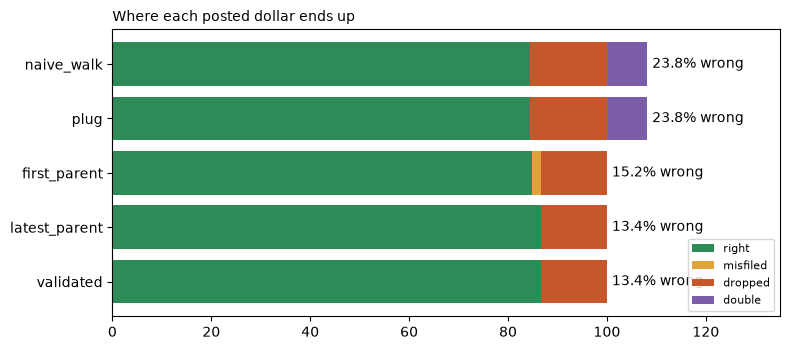

In [8]:
names = list(r["methods"])[::-1]
segs = [("right", "#2e8b57"), ("misfiled", "#e0a23a"), ("dropped", "#c8562b"), ("double", "#7b5ea7")]
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, k in enumerate(names):
    x = 0.0
    for key, col in segs:
        v = 100 * r["methods"][k][key]
        ax.barh(i, v, left=x, color=col, label=key if i == 0 else None)
        x += v
    ax.text(x + 1, i, f"{100 * r['methods'][k]['wrong']:.1f}% wrong", va="center")
ax.set_yticks(range(len(names)), names)
ax.set_xlim(0, 135)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Where each posted dollar ends up", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- "Regions sum to the total" passes for every method: it is a consistency check, not a correctness check.
- A recursive walk counts moved cost centres twice and drops orphans, cycles, unknown codes and area-level postings.
- A plug ties the total and hides a gross error several times its size.
- Validate the extract first (multi-parent, orphan, cycle, unknown code) and name what cannot be placed.
- The unplaced share is fixed in the source hierarchy, not in the roll-up.

## 8. Try your own

In [9]:
# w = make_world(seed=1)                    # another fictional hierarchy
# print(defects(w))
# print(rollup(w, "validated"))
# print(breakdown(w, "first_parent"))

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version rolls the
hierarchy up with any of the five methods next to the truth: `pip install -r requirements.txt && streamlit run app.py`.